# SuddWatch — Phase 2: Pipeline Execution & Visual Diagnostics

**04-652 AI System Design · Assignment 2 · Carnegie Mellon University Africa** — Jok Akech Atem Mabior

This notebook executes the strategy defined in [`phase1_strategy/Phase1_Strategy_Report.pdf`](../../phase1_strategy/Phase1_Strategy_Report.pdf)
on the same raw panel, using the scikit-learn `Pipeline` / `ColumnTransformer` defined in [`src/pipeline_builder.py`](../../src/pipeline_builder.py).

| Section | Phase 1 reference | Output |
|---|---|---|
| 1. Load & reproduce the Phase 1 audit | III-A–C | Fig 1.1 |
| 2. Temporal split (before any fitting) | VI-A–D | Fig 1.2 |
| 3. Outlier capping | IV-C–D | Fig 2.1 |
| 4. Association & collinearity | IV-E–F | Figs 3.1, 3.2, 3.3 |
| 5. Transformation & scaling | V-B | Fig 4.1 |
| 6. Full pipeline: fit on `X_train`, transform val/test | VI-E | `data/processed/` |
| 7. PCA diagnostic | V-B | Fig 5.1 |
| 8. Output verification & strategy-vs-reality checks | — | `phase2_summary.json` |

**Leakage rule used throughout:** every statistic (imputation medians, capping bounds, scalers, encoders, PCA, MI, correlations) is computed on
**training rows only**. The test set is only ever `transform`ed — it is never scored or inspected in this phase.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold, TimeSeriesSplit, cross_val_score
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pipeline_builder.py").exists())
import sys; sys.path.insert(0, str(ROOT))
from src import pipeline_builder as PB
from src.transformers import OutlierCapper, log1p_percent

FIG, PROC = ROOT / "figures", ROOT / "data/processed"
FIG.mkdir(exist_ok=True); PROC.mkdir(exist_ok=True)
SEED = 0
# Validated two-colour palette (blue / orange) + neutral gray, as in the Phase 1 figures
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#9aa5b1", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e6e3",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False})
def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white"); plt.show()
print("project root:", ROOT)

project root: C:\Users\HP\Downloads\SuddWatch_Datasets


## 1. Load the raw panel and reproduce the Phase 1 audit

Phase 2 must start from exactly the data Phase 1 audited. The cell below re-computes N, P and baseline missingness and **asserts**
they equal the values stored in `phase1_strategy/audit/audit_summary.json`.

In [2]:
raw = pd.read_csv(ROOT / "data/raw/suddwatch_panel_unprocessed.csv", parse_dates=["window_start", "issue_date"])
P1 = json.loads((ROOT / "phase1_strategy/audit/audit_summary.json").read_text())
N, P = raw.shape
overall_missing = round(100 * raw.isna().sum().sum() / raw.size, 2)
complete_rows = int(raw.notna().all(axis=1).sum())
assert (N, P) == (P1["N"], P1["P_total_columns"]), "panel differs from Phase 1"
assert overall_missing == P1["overall_missing_pct"] and complete_rows == P1["complete_rows"]
print(f"N x P = {N:,} x {P}  |  missing cells = {overall_missing}%  |  complete rows = {complete_rows:,}  -> matches Phase 1")
raw.isna().sum()[raw.isna().sum() > 0].to_frame("n_missing").assign(pct=lambda d: (100 * d.n_missing / N).round(2))

N x P = 23,305 x 26  |  missing cells = 1.46%  |  complete rows = 19,708  -> matches Phase 1


,n_missing,pct
water_frac,2145,9.20
water_frac_lag1,2224,9.54
water_frac_lag2,2303,9.88
y_flood_2_4wk,2145,9.20


### Fig 1.1 — Missingness pattern heatmap
Left: the full **row × column** missingness matrix (rows ordered by issue date). Middle: the same gaps by county × issue window, which
shows the Sentinel-1 acquisition-plan mechanism diagnosed as MAR in Phase 1. Right: per-column missing percentage.

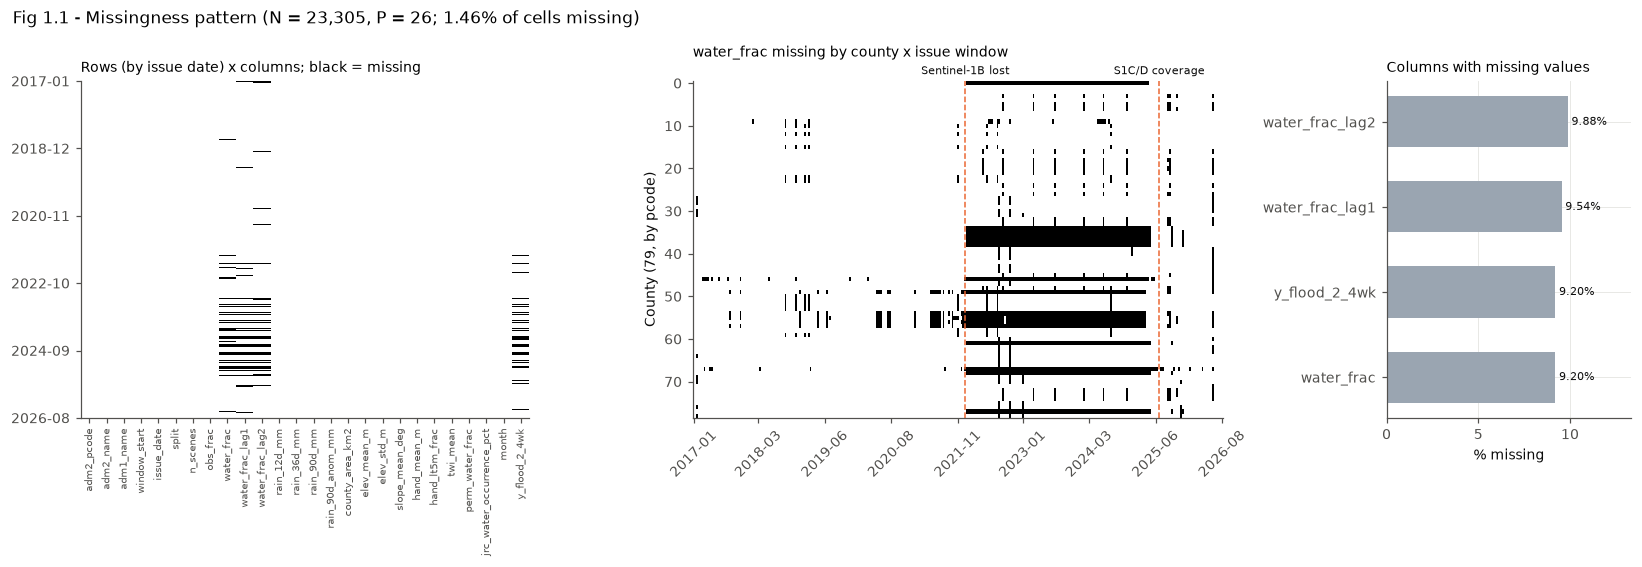

In [3]:
cols = list(raw.columns)
M = raw.sort_values(["issue_date", "adm2_pcode"])[cols].isna().values
piv = raw.assign(m=raw.water_frac.isna()).pivot_table(index="adm2_pcode", columns="issue_date", values="m", aggfunc="max")
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw={"width_ratios": [2.2, 2.6, 1.2]})
ax[0].imshow(M, aspect="auto", cmap="Greys", interpolation="nearest")
ax[0].set_xticks(range(len(cols))); ax[0].set_xticklabels(cols, rotation=90, fontsize=6.5)
yt = np.linspace(0, N - 1, 6).astype(int)
dates = raw.sort_values(["issue_date", "adm2_pcode"])["issue_date"].dt.strftime("%Y-%m").values
ax[0].set_yticks(yt); ax[0].set_yticklabels(dates[yt]); ax[0].grid(False)
ax[0].set_title("Rows (by issue date) x columns; black = missing", loc="left", fontsize=9)
ax[1].imshow(piv.values, aspect="auto", cmap="Greys", interpolation="nearest"); ax[1].grid(False)
xt = np.linspace(0, piv.shape[1] - 1, 9).astype(int)
ax[1].set_xticks(xt); ax[1].set_xticklabels([str(piv.columns[i].date())[:7] for i in xt], rotation=45)
ax[1].set_ylabel("County (79, by pcode)")
for d, lab in [("2021-12-23", "Sentinel-1B lost"), ("2025-06-30", "S1C/D coverage")]:
    x = np.searchsorted(piv.columns.values, np.datetime64(d)); ax[1].axvline(x, color=ORANGE, ls="--", lw=1)
    ax[1].text(x, -1.5, lab, color=INK, fontsize=7, va="bottom", ha="center", clip_on=False)
ax[1].set_title("water_frac missing by county x issue window", loc="left", fontsize=9, pad=16)
pm = raw.isna().mean().mul(100).sort_values(); pm = pm[pm > 0]
ax[2].barh(pm.index, pm.values, color=GRAY, height=0.6)
for i, v in enumerate(pm.values): ax[2].text(v + 0.2, i, f"{v:.2f}%", va="center", fontsize=7.5, color=INK)
ax[2].set_xlabel("% missing"); ax[2].set_xlim(0, pm.max() * 1.35); ax[2].set_title("Columns with missing values", loc="left", fontsize=9)
fig.suptitle(f"Fig 1.1 - Missingness pattern (N = {N:,}, P = {P}; {overall_missing}% of cells missing)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "fig1_1_missingness_heatmap.png")

## 1b. Dataset snapshots and full descriptive statistics

**Structure.** The data is a **panel time series** in long format: every one of the 79 counties is observed every 12 days
(one Sentinel-1 window) from January 2017 to August 2026, so each row is *one county at one point in time*. Forecasting is framed as
supervised classification on this panel: features describe the county up to the forecast date, and the label is the county's water
state two windows later. The cells below show the structure, raw rows, one county as a time series, full statistics for every column,
and the source datasets the panel was assembled from. These statistics are descriptive (the Phase 1 audit level); every statistic
that is *fitted* still uses training rows only.

In [4]:
from IPython.display import display
n_c, n_w = raw["adm2_pcode"].nunique(), raw["window_start"].nunique()
per_county = raw.groupby("adm2_pcode").size()
print(f"Panel time series: {n_c} counties x {n_w} twelve-day windows = {len(raw):,} rows "
      f"(issue dates {raw.issue_date.min().date()} -> {raw.issue_date.max().date()})")
print(f"rows per county: min {per_county.min()}, max {per_county.max()}  (balanced panel)")
print("rows per year:", raw["issue_date"].dt.year.value_counts().sort_index().to_dict())
schema = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_%": (100 * raw.isna().mean()).round(2),
    "n_unique": raw.nunique(),
    "example_value": raw.iloc[0].astype(str),
})
schema

Panel time series: 79 counties x 295 twelve-day windows = 23,305 rows (issue dates 2017-01-12 -> 2026-08-29)
rows per county: min 295, max 295  (balanced panel)
rows per year: {2017: 2370, 2018: 2370, 2019: 2449, 2020: 2370, 2021: 2449, 2022: 2370, 2023: 2528, 2024: 2370, 2025: 2370, 2026: 1659}


,dtype,non_null,missing,missing_%,n_unique,example_value
adm2_pcode,str,23305,0,0.00,79,SS0001
adm2_name,str,23305,0,0.00,79,Abyei
adm1_name,str,23305,0,0.00,11,Abyei Region
window_start,datetime64[us],23305,0,0.00,295,2017-01-01 00:00:00
issue_date,datetime64[us],23305,0,0.00,295,2017-01-12 00:00:00
split,str,23305,0,0.00,3,train
n_scenes,int64,23305,0,0.00,53,61
obs_frac,float64,23305,0,0.00,2820,1.0
water_frac,float64,21160,2145,9.20,16798,0.0018395519111257
water_frac_lag1,float64,21081,2224,9.54,16734,NaN


### Snapshot: first rows, a random sample, and one county as a time series

In [5]:
pd.set_option("display.max_columns", 40, "display.width", 250)
print("First 8 rows (sorted by issue date, then county):")
display(raw.head(8))
print("Random sample of 8 rows (seed 0):")
display(raw.sample(8, random_state=SEED).sort_values(["issue_date", "adm2_pcode"]))

First 8 rows (sorted by issue date, then county):


,adm2_pcode,adm2_name,adm1_name,window_start,issue_date,split,n_scenes,obs_frac,water_frac,water_frac_lag1,water_frac_lag2,rain_12d_mm,rain_36d_mm,rain_90d_mm,rain_90d_anom_mm,county_area_km2,elev_mean_m,elev_std_m,slope_mean_deg,hand_mean_m,hand_lt5m_frac,twi_mean,perm_water_frac,jrc_water_occurrence_pct,month,y_flood_2_4wk
0,SS0001,Abyei,Abyei Region,2017-01-01,2017-01-12,train,61,1.000000,0.001840,NaN,NaN,0.000000,0.000000,29.426460,-13.681168,10495.850579,406.437810,4.356213,0.188144,0.418888,1.000000,13.461179,0.000000,0.002059,1,0.0
1,SS0101,Juba,Central Equatoria,2017-01-01,2017-01-12,train,61,1.000000,0.002987,NaN,NaN,0.048991,3.417387,152.696904,-4.863781,18366.514881,608.315813,123.558091,1.413777,12.109128,0.400470,10.709651,0.001570,0.173305,1,1.0
2,SS0102,Kajo-keji,Central Equatoria,2017-01-01,2017-01-12,train,61,0.999765,0.000104,NaN,NaN,0.307276,8.799592,209.911066,-8.630659,2516.104546,854.426473,102.243573,2.724411,23.848683,0.172310,9.659367,0.000415,0.046037,1,0.0
3,SS0103,Lainya,Central Equatoria,2017-01-01,2017-01-12,train,61,0.998792,0.000000,NaN,NaN,1.054249,12.096501,202.486863,13.876498,3498.916146,865.683229,69.081558,1.427083,12.631249,0.254675,10.163201,0.000000,0.000015,1,0.0
4,SS0104,Morobo,Central Equatoria,2017-01-01,2017-01-12,train,61,1.000000,0.000000,NaN,NaN,3.935038,8.786965,272.668984,23.867619,1308.941909,1070.234632,90.105211,2.585163,22.995872,0.186573,9.639353,0.000000,0.000000,1,0.0
5,SS0105,Terekeka,Central Equatoria,2017-01-01,2017-01-12,train,61,0.999956,0.002854,NaN,NaN,0.554500,1.187643,94.591653,-5.337130,10672.129966,468.840618,29.072155,0.416559,3.914786,0.708417,12.130615,0.000566,0.149565,1,0.0
6,SS0106,Yei,Central Equatoria,2017-01-01,2017-01-12,train,61,1.000000,0.000000,NaN,NaN,4.401504,12.386477,235.199402,20.827558,6720.548023,845.628890,66.398164,1.405016,12.986853,0.240673,10.216835,0.000000,0.000031,1,0.0
7,SS0201,Budi,Eastern Equatoria,2017-01-01,2017-01-12,train,61,1.000000,0.000591,NaN,NaN,2.349309,8.799980,109.763615,-18.374058,5733.332610,978.559241,356.972910,4.397953,40.547309,0.317810,10.067007,0.000000,0.000002,1,0.0


Random sample of 8 rows (seed 0):


,adm2_pcode,adm2_name,adm1_name,window_start,issue_date,split,n_scenes,obs_frac,water_frac,water_frac_lag1,water_frac_lag2,rain_12d_mm,rain_36d_mm,rain_90d_mm,rain_90d_anom_mm,county_area_km2,elev_mean_m,elev_std_m,slope_mean_deg,hand_mean_m,hand_lt5m_frac,twi_mean,perm_water_frac,jrc_water_occurrence_pct,month,y_flood_2_4wk
3851,SS0712,Ulang,Upper Nile,2018-07-31,2018-08-11,train,64,1.000000,0.000595,0.000984,0.000405,74.761570,126.846636,401.096138,-3.239008,4833.588756,404.451692,2.962467,0.142890,0.479430,0.999441,13.351473,0.000036,0.186207,8,0.0
6190,SS0403,Rumbek Centre,Lakes,2019-07-26,2019-08-06,train,61,0.999997,0.000010,0.000020,0.000000,55.345883,209.556715,545.791371,97.677204,3853.364344,418.862557,9.602749,0.197799,0.815999,0.977457,13.154243,0.000000,0.000096,8,0.0
17846,SS1003,Maridi,Western Equatoria,2024-05-12,2024-05-23,validation,30,0.999800,0.000000,0.000013,0.000013,46.527175,116.534757,189.736138,-143.508281,7681.283577,700.452077,87.332302,1.503634,13.750298,0.222126,10.145646,0.000007,0.001113,5,0.0
17939,SS0106,Yei,Central Equatoria,2024-06-05,2024-06-16,validation,31,1.000000,0.000000,0.000000,0.000000,144.519157,279.019928,414.198510,-11.597234,6720.548023,845.628890,66.398164,1.405016,12.986853,0.240673,10.216835,0.000000,0.000031,6,0.0
18021,SS0203,Kapoeta East,Eastern Equatoria,2024-06-17,2024-06-28,validation,26,0.210618,NaN,NaN,NaN,4.891090,47.442764,279.996638,58.627097,29562.911012,598.349678,206.671119,1.966207,17.335611,0.628686,11.435375,0.000000,0.002195,6,0.0
19843,SS0208,Torit,Eastern Equatoria,2025-03-20,2025-03-31,validation,36,0.999882,0.000029,0.000020,0.000010,23.127856,50.288549,55.775417,-15.584544,5838.570434,797.017068,326.453393,4.264236,39.347486,0.365465,10.205797,0.000000,0.000002,3,0.0
20779,SS0102,Kajo-keji,Central Equatoria,2025-08-11,2025-08-22,test,77,0.999765,0.000055,0.000259,0.000107,88.162617,178.611379,393.284254,-61.011495,2516.104546,854.426473,102.243573,2.724411,23.848683,0.172310,9.659367,0.000415,0.046037,8,0.0
21656,SS0204,Kapoeta North,Eastern Equatoria,2025-12-21,2026-01-01,test,65,0.999988,0.000000,0.000000,0.000021,16.755956,35.507034,234.063128,80.468498,5733.141320,493.614444,54.424326,0.259232,1.777678,0.913741,12.799060,0.000000,0.000012,1,0.0


,issue_date,split,n_scenes,obs_frac,water_frac,water_frac_lag1,rain_36d_mm,rain_90d_anom_mm,y_flood_2_4wk
12656,2022-04-16,train,31,1.000000,0.014322,0.005571,15.671851,-4.027692,1.0
12735,2022-04-28,train,35,0.027569,NaN,0.014322,39.708557,2.290786,0.0
12814,2022-05-10,train,36,1.000000,0.013748,NaN,68.636625,2.515668,1.0
12893,2022-05-22,train,27,1.000000,0.012341,0.013748,94.401271,7.089321,0.0
12972,2022-06-03,train,28,1.000000,0.013352,0.012341,86.321485,-16.662654,0.0
13051,2022-06-15,train,29,1.000000,0.012312,0.013352,96.634904,-25.253542,1.0
13130,2022-06-27,train,31,1.000000,0.013178,0.012312,105.461425,-30.196170,1.0
13209,2022-07-09,train,34,1.000000,0.014268,0.013178,154.301082,-19.311419,1.0
13288,2022-07-21,train,36,1.000000,0.013401,0.014268,157.996565,-37.801429,0.0
13367,2022-08-02,train,24,1.000000,0.014492,0.013401,189.688245,-15.226892,1.0


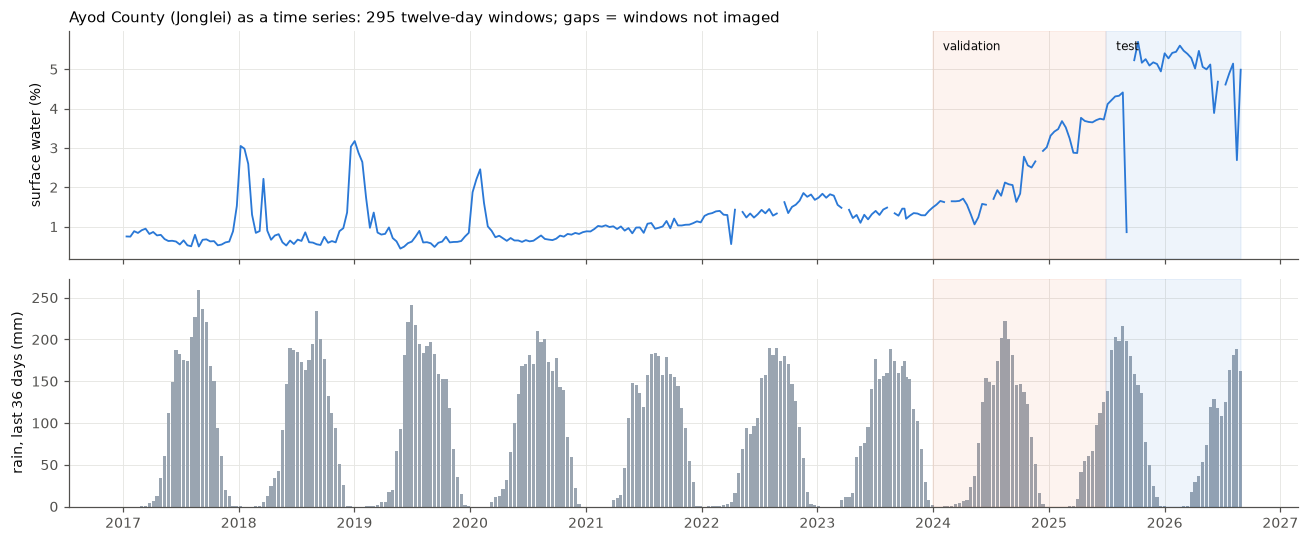

In [6]:
# One county followed through time: Ayod (SS0302, Jonglei, core Sudd). water_frac_lag1 on each row
# equals the previous row's water_frac, and Y looks two windows ahead.
ayod = raw[raw["adm2_pcode"] == "SS0302"].sort_values("issue_date")
cols_ts = ["issue_date", "split", "n_scenes", "obs_frac", "water_frac", "water_frac_lag1", "rain_36d_mm", "rain_90d_anom_mm", "y_flood_2_4wk"]
display(ayod[cols_ts].iloc[160:172])
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(ayod["issue_date"], 100 * ayod["water_frac"], color=BLUE, lw=1.2)
ax[0].set_ylabel("surface water (%)")
ax[1].bar(ayod["issue_date"], ayod["rain_36d_mm"], width=10, color=GRAY)
ax[1].set_ylabel("rain, last 36 days (mm)")
for a in ax:
    a.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2025-07-01"), color=ORANGE, alpha=0.08)
    a.axvspan(pd.Timestamp("2025-07-01"), raw["issue_date"].max(), color=BLUE, alpha=0.08)
ax[0].text(pd.Timestamp("2024-02-01"), ax[0].get_ylim()[1] * 0.92, "validation", fontsize=8, color=INK)
ax[0].text(pd.Timestamp("2025-08-01"), ax[0].get_ylim()[1] * 0.92, "test", fontsize=8, color=INK)
ax[0].set_title("Ayod County (Jonglei) as a time series: 295 twelve-day windows; gaps = windows not imaged", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

### Full descriptive statistics — numeric columns (all rows)

In [7]:
numc = raw.select_dtypes("number").columns.drop("y_flood_2_4wk")
desc = raw[numc].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc.insert(1, "missing", raw[numc].isna().sum())
desc["skew"] = raw[numc].skew()
desc["kurtosis"] = raw[numc].kurt()
desc["n_unique"] = raw[numc].nunique()
desc.round(4)

,count,missing,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurtosis,n_unique
n_scenes,23305.0,0,54.1695,16.9914,22.0000,24.0000,30.0000,36.0000,60.0000,66.0000,74.0000,105.0000,113.0000,0.0745,-0.3277,53
obs_frac,23305.0,0,0.8988,0.2689,0.0000,0.0000,0.0049,0.9996,1.0000,1.0000,1.0000,1.0000,1.0000,-2.6245,5.4259,2820
water_frac,21160.0,2145,0.0051,0.0174,0.0000,0.0000,0.0000,0.0000,0.0005,0.0039,0.0214,0.0669,0.7409,11.6749,247.3782,16798
water_frac_lag1,21081.0,2224,0.0051,0.0173,0.0000,0.0000,0.0000,0.0000,0.0005,0.0039,0.0212,0.0655,0.7409,11.7621,251.2613,16734
water_frac_lag2,21002.0,2303,0.0051,0.0173,0.0000,0.0000,0.0000,0.0000,0.0005,0.0039,0.0211,0.0649,0.7409,11.8245,253.7450,16671
rain_12d_mm,23305.0,0,31.9415,29.9267,0.0000,0.0000,0.0000,0.9868,28.2367,55.8079,83.6654,104.0335,170.2864,0.5429,-0.7316,20445
rain_36d_mm,23305.0,0,95.4337,81.4700,0.0000,0.0000,0.0000,8.2570,91.5356,166.7507,226.6619,260.1521,361.1861,0.2669,-1.2739,21652
rain_90d_mm,23305.0,0,235.7444,180.9800,0.0000,0.0026,0.7513,54.1331,227.0268,395.1941,526.1801,585.6502,753.1186,0.2024,-1.2807,22962
rain_90d_anom_mm,23305.0,0,5.0159,40.9054,-193.3909,-107.3568,-59.6814,-14.0161,0.8055,23.5212,75.9036,122.6302,270.9084,0.3239,2.6958,23304
county_area_km2,23305.0,0,8137.8598,8126.2039,754.6804,754.6804,1610.9415,4396.5876,5872.9373,9608.0270,19212.8275,62010.5687,62010.5687,4.2854,23.3438,79


### Full descriptive statistics — categorical, datetime and target columns

In [8]:
cat = raw[["adm2_pcode", "adm2_name", "adm1_name", "split"]].astype(str).describe().T
print("Categorical columns:"); display(cat)
print("Rows per state (adm1_name):")
display(raw["adm1_name"].value_counts().rename_axis("state").to_frame("rows").assign(counties=raw.groupby("adm1_name")["adm2_pcode"].nunique()))
print("Datetime columns:")
display(pd.DataFrame({c: {"min": raw[c].min().date(), "max": raw[c].max().date(), "n_unique": raw[c].nunique(),
                          "step_days": int(raw[c].drop_duplicates().sort_values().diff().dt.days.mode()[0])}
                      for c in ["window_start", "issue_date"]}).T)
print("Target y_flood_2_4wk by split (NaN = target window not imaged):")
display(pd.crosstab(raw["split"], raw["y_flood_2_4wk"].fillna(-1).map({0.0: "Y=0", 1.0: "Y=1", -1: "missing"}),
                    margins=True).reindex(["train", "validation", "test", "All"]))

Categorical columns:


,count,unique,top,freq
adm2_pcode,23305,79,SS0001,295
adm2_name,23305,79,Abyei,295
adm1_name,23305,11,Upper Nile,3540
split,23305,3,train,16906


Rows per state (adm1_name):


,rows,counties
state,,
Upper Nile,3540,12
Jonglei,3245,11
Western Equatoria,2950,10
Unity,2655,9
Eastern Equatoria,2360,8
Lakes,2360,8
Central Equatoria,1770,6
Warrap,1770,6
Northern Bahr el Ghazal,1475,5


Datetime columns:


,min,max,n_unique,step_days
window_start,2017-01-01,2026-08-18,295,12
issue_date,2017-01-12,2026-08-29,295,12


Target y_flood_2_4wk by split (NaN = target window not imaged):


y_flood_2_4wk,Y=0,Y=1,missing,All
split,,,,
train,12563,2987,1356,16906
validation,1876,1072,686,3634
test,1682,980,103,2765
All,16121,5039,2145,23305


### Source datasets the panel was assembled from (`data/raw/`)

In [9]:
sources = {
    "Sentinel-1 water by county x window (Earth Engine)": ROOT / "data/raw/gee/s1_water_by_county_window.csv",
    "CHIRPS daily rainfall by county 2001-2026 (Earth Engine)": ROOT / "data/raw/gee/chirps_daily_by_county.csv",
    "Static terrain / hydrology by county (SRTM, MERIT, JRC)": ROOT / "data/raw/gee/static_terrain_by_county.csv",
    "County P75 thresholds (training windows only)": ROOT / "data/raw/county_thresholds_train_only.csv",
}
for title, path in sources.items():
    d = pd.read_csv(path)
    print(f"\n=== {title}\n    {path.relative_to(ROOT)} : {d.shape[0]:,} rows x {d.shape[1]} columns, "
          f"{d.isna().sum().sum():,} missing cells")
    display(d.head(3))
    display(d.describe().T.round(3))


=== Sentinel-1 water by county x window (Earth Engine)
    data\raw\gee\s1_water_by_county_window.csv : 23,463 rows x 7 columns, 0 missing cells


,adm2_pcode,window_start,window_end,n_scenes,obs_km2,eligible_km2,water_km2
0,SS0101,2017-01-01,2017-01-12,61,18366.940520,15662.097243,46.782145
1,SS0102,2017-01-01,2017-01-12,61,2515.513382,1528.773425,0.158566
2,SS0103,2017-01-01,2017-01-12,61,3494.689990,2965.263866,0.000000


,count,mean,std,min,25%,50%,75%,max
n_scenes,23463.0,54.347,17.072,22.0,36.000,60.000,66.000,113.000
obs_km2,23463.0,7082.745,7115.481,0.0,3566.608,5572.223,8792.106,62012.601
eligible_km2,23463.0,6602.936,6410.398,0.0,3561.278,5185.585,7662.505,54889.844
water_km2,23463.0,28.215,85.033,0.0,0.040,2.088,20.141,5101.382



=== CHIRPS daily rainfall by county 2001-2026 (Earth Engine)
    data\raw\gee\chirps_daily_by_county.csv : 740,546 rows x 3 columns, 0 missing cells


,adm2_pcode,date,precip_mm
0,SS0001,2001-01-01,0.0
1,SS0001,2001-01-02,0.0
2,SS0001,2001-01-03,0.0


...

,adm2_pcode,elev_m_mean,elev_m_stdDev,slope_deg_mean,hand_m_mean,hand_lt5_frac_mean,twi_mean,perm_water_frac_mean,water_occurrence_pct_mean
0,SS0101,608.315813,123.558091,1.413777,12.109128,0.400470,10.709651,0.001570,0.173305
1,SS0102,854.426473,102.243573,2.724411,23.848683,0.172310,9.659367,0.000415,0.046037
2,SS0103,865.683229,69.081558,1.427083,12.631249,0.254675,10.163201,0.000000,0.000015


,count,mean,std,min,25%,50%,75%,max
elev_m_mean,79.0,512.848,168.628,392.574,404.670,432.345,567.509,1144.314
elev_m_stdDev,79.0,50.810,87.879,1.700,3.111,16.699,58.420,548.878
slope_deg_mean,79.0,0.760,1.086,0.128,0.165,0.246,1.051,6.606
hand_m_mean,79.0,6.525,10.774,0.252,0.458,1.493,9.889,68.199
hand_lt5_frac_mean,79.0,0.741,0.319,0.172,0.383,0.935,0.999,1.000
twi_mean,79.0,12.238,1.353,9.639,10.782,12.946,13.356,13.487
perm_water_frac_mean,79.0,0.001,0.002,0.000,0.000,0.000,0.001,0.010
water_occurrence_pct_mean,79.0,0.157,0.269,0.000,0.001,0.019,0.202,1.255



=== County P75 thresholds (training windows only)
    data\raw\county_thresholds_train_only.csv : 79 rows x 6 columns, 0 missing cells


,adm2_pcode,thr_p75,thr_floor,y_threshold_frac,n_train_obs,adm2_name
0,SS0001,0.002471,0.000095,0.002471,152,Abyei
1,SS0101,0.001494,0.000064,0.001494,214,Juba
2,SS0102,0.000104,0.000654,0.000654,214,Kajo-keji


,count,mean,std,min,25%,50%,75%,max
thr_p75,79.0,0.004,0.005,0.0,0.0,0.001,0.005,0.019
thr_floor,79.0,0.000,0.000,0.0,0.0,0.000,0.000,0.001
y_threshold_frac,79.0,0.004,0.005,0.0,0.0,0.001,0.005,0.019
n_train_obs,79.0,197.241,27.595,128.0,207.0,211.000,212.000,214.000


## 2. Temporal split — performed before any fitting (Phase 1, Section VI)

* train: issue date < 2024-01-01 · validation: 2024-01-01 – 2025-06-30 · test: ≥ 2025-07-01
* rows without a label are excluded (Y is never imputed — Phase 1, Table V)
* **purge gap**: the last two issue windows before each boundary are dropped, because Y looks two windows ahead and would otherwise overlap the next split.

In [10]:
TARGET, GAP = PB.TARGET, 2
lab = raw.dropna(subset=[TARGET]).copy()
lab[TARGET] = lab[TARGET].astype(int)
windows = np.sort(raw["window_start"].unique())
def last_k(before, k=GAP):
    w = windows[windows < np.datetime64(before)]
    return set(w[-k:])
purged = last_k("2024-01-01") | last_k("2025-07-01")
n_purged = int(lab["window_start"].isin(purged).sum())
lab = lab[~lab["window_start"].isin(purged)].sort_values(["issue_date", "adm2_pcode"]).reset_index(drop=True)
parts = {s: lab[lab.split == s] for s in ["train", "validation", "test"]}
X_train, y_train = parts["train"].drop(columns=[TARGET]), parts["train"][TARGET]
X_val, y_val = parts["validation"].drop(columns=[TARGET]), parts["validation"][TARGET]
X_test, y_test = parts["test"].drop(columns=[TARGET]), parts["test"][TARGET]
split_tbl = pd.DataFrame({s: {"rows": len(d), "share_%": round(100 * len(d) / len(lab), 1), "positives": int(d[TARGET].sum()),
                              "pos_rate_%": round(100 * d[TARGET].mean(), 1), "first": d.issue_date.min().date(), "last": d.issue_date.max().date()}
                          for s, d in parts.items()}).T
print(f"labelled rows {raw[TARGET].notna().sum():,} -> purged {n_purged:,} rows in {len(purged)} boundary windows -> {len(lab):,} used")
split_tbl

labelled rows 21,160 -> purged 282 rows in 4 boundary windows -> 20,878 used


,rows,share_%,positives,pos_rate_%,first,last
train,15424,73.9,2926,19.0,2017-01-12,2023-12-07
validation,2792,13.4,1030,36.9,2024-01-12,2025-06-11
test,2662,12.8,980,36.8,2025-07-17,2026-08-29


### Fig 1.2 — Target distribution (class balance by split)

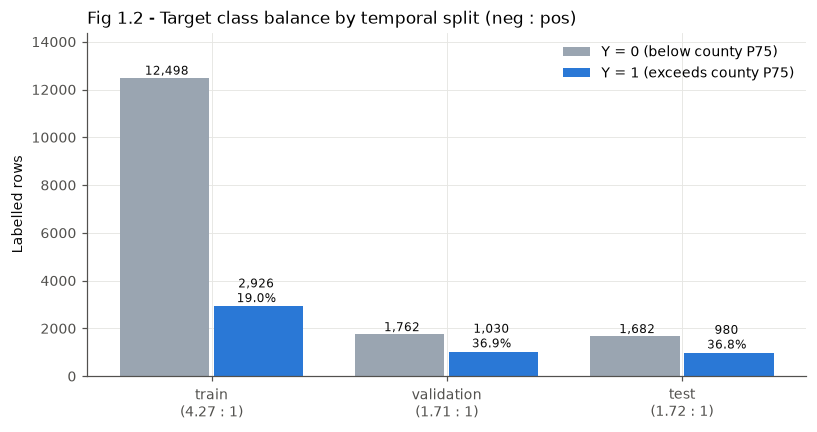

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(3); w = 0.38
neg = [int((parts[s][TARGET] == 0).sum()) for s in parts]; pos = [int(parts[s][TARGET].sum()) for s in parts]
ax.bar(x - w / 2 - 0.01, neg, w, color=GRAY, label="Y = 0 (below county P75)")
ax.bar(x + w / 2 + 0.01, pos, w, color=BLUE, label="Y = 1 (exceeds county P75)")
for i, (a, b) in enumerate(zip(neg, pos)):
    ax.text(i - w / 2, a, f"{a:,}", ha="center", va="bottom", fontsize=8, color=INK)
    ax.text(i + w / 2, b, f"{b:,}\n{100 * b / (a + b):.1f}%", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n({a / max(b, 1):.2f} : 1)" for s, a, b in zip(parts, neg, pos)])
ax.set_ylabel("Labelled rows"); ax.legend(loc="upper right"); ax.set_ylim(0, max(neg) * 1.15)
ax.set_title("Fig 1.2 - Target class balance by temporal split (neg : pos)", loc="left", fontsize=11)
fig.tight_layout(); save(fig, "fig1_2_target_distribution.png")

## 3. Outlier capping (Phase 1, Section IV-C/D)

Rule by distribution shape, **assigned in Phase 1 and kept fixed** (`CAP_Z` / `CAP_IQR` in `src/pipeline_builder.py`): |skew| ≤ 0.5 → winsorise at
μ ± 3σ; |skew| > 0.5 → 1.5 × IQR fences. Bounds are learned on the Phase 2 training rows.
Only dynamic rainfall features are capped. Water fractions are flagged but not capped (outliers are the floods being predicted) and static
terrain extremes are real counties. The cappers are the same `OutlierCapper` objects used inside the pipeline, fitted on `X_train` only.

In [12]:
rain = ["rain_12d_mm", "rain_36d_mm", "rain_90d_mm", "rain_90d_anom_mm"]
rules = {c: ("z" if c in PB.CAP_Z else "iqr") for c in rain}       # pre-registered in Phase 1 (src/pipeline_builder.py)
cappers = {c: OutlierCapper([c], method=m).fit(X_train) for c, m in rules.items()}
P1_skew = pd.read_csv(ROOT / "phase1_strategy/audit/B_skewness_outliers_train.csv").set_index("feature")["skew"].round(2).to_dict()
cap_rows = []
for c, cp in cappers.items():
    lo, hi = float(cp.lower_[c]), float(cp.upper_[c])
    cap_rows.append({"feature": c, "skew": round(stats.skew(X_train[c]), 2), "phase1_skew": P1_skew[c], "rule": rules[c], "lower": round(lo, 1), "upper": round(hi, 1),
                     "n_capped_train": int(((X_train[c] < lo) | (X_train[c] > hi)).sum()),
                     "pct_capped_train": round(100 * ((X_train[c] < lo) | (X_train[c] > hi)).mean(), 2),
                     "kept_after_collinearity": c not in PB.DROP_COLLINEAR})
cap_tbl = pd.DataFrame(cap_rows); cap_tbl

,feature,skew,phase1_skew,rule,lower,upper,n_capped_train,pct_capped_train,kept_after_collinearity
0,rain_12d_mm,0.49,0.50,iqr,-83.4,142.1,2,0.01,False
1,rain_36d_mm,0.21,0.24,z,-148.5,346.0,0,0.00,True
2,rain_90d_mm,0.14,0.16,z,-306.4,794.8,0,0.00,False
3,rain_90d_anom_mm,0.49,0.48,z,-115.2,129.6,184,1.19,True


### Fig 2.1 — Outlier box plots, raw vs capped (training rows)

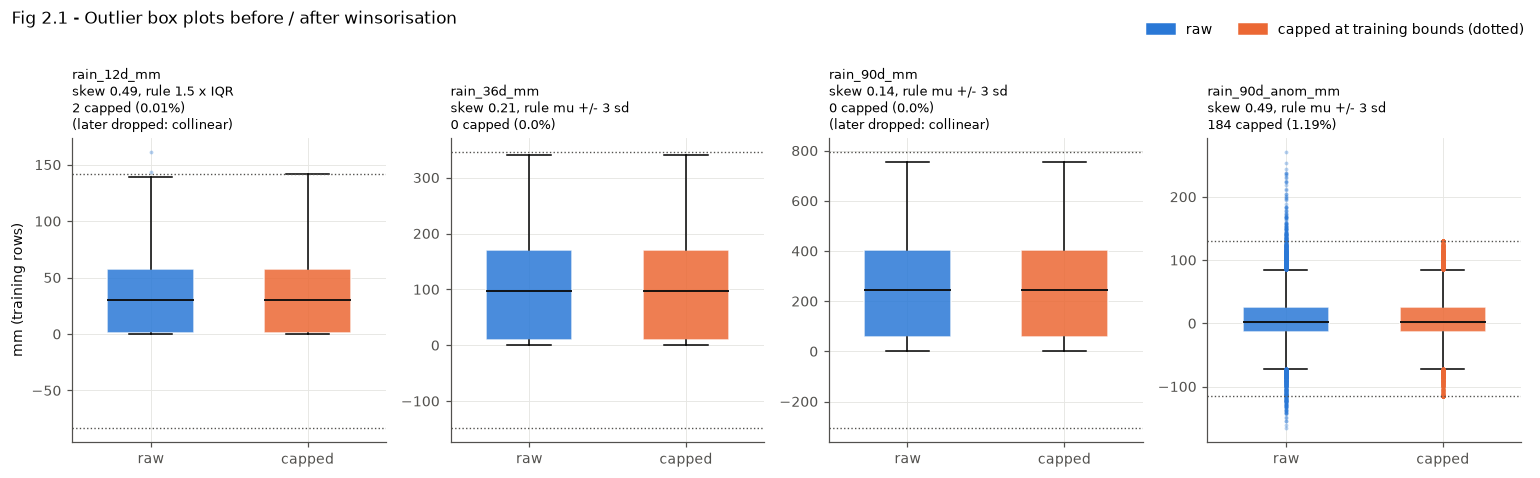

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
for ax, r in zip(axes, cap_rows):
    c = r["feature"]; capped = cappers[c].transform(X_train)[c]
    bp = ax.boxplot([X_train[c], capped], positions=[0, 1], widths=0.55, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.35, markeredgewidth=0),
                    medianprops=dict(color=INK, lw=1.2))
    for patch, col in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(col); patch.set_alpha(0.85); patch.set_edgecolor("white")
    for fl, col in zip(bp["fliers"], [BLUE, ORANGE]): fl.set_markerfacecolor(col)
    ax.axhline(r["upper"], color=MUTED, ls=":", lw=0.9); ax.axhline(r["lower"], color=MUTED, ls=":", lw=0.9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["raw", "capped"])
    rule = "mu +/- 3 sd" if r["rule"] == "z" else "1.5 x IQR"
    note = "" if r["kept_after_collinearity"] else "\n(later dropped: collinear)"
    ax.set_title(f"{c}\nskew {r['skew']}, rule {rule}\n{r['n_capped_train']} capped ({r['pct_capped_train']}%){note}", fontsize=8.5, loc="left")
axes[0].set_ylabel("mm (training rows)")
fig.legend(handles=[Patch(color=BLUE, label="raw"), Patch(color=ORANGE, label="capped at training bounds (dotted)")],
           loc="upper right", ncol=2, bbox_to_anchor=(1, 1.02))
fig.suptitle("Fig 2.1 - Outlier box plots before / after winsorisation", x=0.01, ha="left", fontsize=11, y=1.02)
fig.tight_layout(); save(fig, "fig2_1_outlier_boxplots.png")

## 4. Association and collinearity (Phase 1, Section IV-E/F)

Computed on **training rows only**. The Phase 1 report specified Spearman ρ between features (most are non-normal), the |ρ| ≥ 0.85 screen,
the lower-MI drop rule and the VIF > 10 loop. **The pipeline applies the Phase 1 drop list unchanged** (pre-registered); the rule is
re-run below on the Phase 2 training rows only as a stability check. The momentum feature `water_frac_delta = water_frac − water_frac_lag1` promised in Phase 1 is
added here and screened with the same rule.

In [14]:
tr = X_train.assign(water_frac_delta=X_train.water_frac - X_train.water_frac_lag1)
num = ["obs_frac", "water_frac", "water_frac_lag1", "water_frac_lag2", "water_frac_delta", "rain_12d_mm", "rain_36d_mm", "rain_90d_mm",
       "rain_90d_anom_mm", "county_area_km2", "elev_mean_m", "elev_std_m", "slope_mean_deg", "hand_mean_m", "hand_lt5m_frac", "twi_mean",
       "perm_water_frac", "jrc_water_occurrence_pct", "n_scenes", "month"]
rho = tr[num].corr(method="spearman")
mask_ok = tr[num].notna().all(axis=1)
mi = pd.Series(mutual_info_classif(tr.loc[mask_ok, num], y_train[mask_ok], random_state=SEED), index=num)
mi["adm1_name"] = mutual_info_classif(pd.factorize(tr["adm1_name"])[0].reshape(-1, 1), y_train, discrete_features=True, random_state=SEED)[0]
pairs = sorted([(a, b, rho.loc[a, b]) for i, a in enumerate(num) for b in num[i + 1:] if abs(rho.loc[a, b]) >= 0.85], key=lambda t: -abs(t[2]))
kept, dropped = [c for c in num if c != "month"], []
for a, b, r in pairs:
    if a in kept and b in kept:
        d = a if mi[a] < mi[b] else b; kept.remove(d); dropped.append((d, b if d == a else a, round(r, 3)))
phase2_drop = sorted(d for d, *_ in dropped)
print("drop list recomputed on Phase 2 training rows:", phase2_drop)
print("Phase 1 drop list:                            ", sorted(PB.DROP_COLLINEAR))
print("identical:", phase2_drop == sorted(PB.DROP_COLLINEAR))
pipeline_drop = sorted(PB.DROP_COLLINEAR)          # what the pipeline actually removes (pre-registered in Phase 1)
p1 = pd.read_csv(ROOT / "phase1_strategy/audit/C_collinearity_drop_list.csv")
p1["partner"] = p1["reason"].str.extract(r"with (\S+)")[0]
p1["rho_phase2"] = [round(rho.loc[d, k], 3) for d, k in zip(p1["feature"], p1["partner"])]
static_feats = ["elev_mean_m", "elev_std_m", "slope_mean_deg", "hand_mean_m", "hand_lt5m_frac", "twi_mean"]
print("MI of the terrain block (training rows):", mi[static_feats].round(4).to_dict())
print("momentum feature max |rho| with retained features:", round(rho.loc["water_frac_delta", [k for k in kept if k != "water_frac_delta"]].abs().max(), 3),
      "| MI:", round(mi["water_frac_delta"], 4))
p1[["feature", "partner", "reason", "rho_phase2"]].rename(columns={"feature": "dropped (Phase 1 rule)", "reason": "Phase 1 evidence", "rho_phase2": "rho on Phase 2 train"})

drop list recomputed on Phase 2 training rows: ['elev_mean_m', 'elev_std_m', 'hand_lt5m_frac', 'hand_mean_m', 'perm_water_frac', 'rain_12d_mm', 'rain_90d_mm', 'slope_mean_deg', 'water_frac_lag1', 'water_frac_lag2']
Phase 1 drop list:                             ['elev_mean_m', 'elev_std_m', 'hand_mean_m', 'perm_water_frac', 'rain_12d_mm', 'rain_90d_mm', 'slope_mean_deg', 'twi_mean', 'water_frac_lag1', 'water_frac_lag2']
identical: False
MI of the terrain block (training rows): {'elev_mean_m': 0.0376, 'elev_std_m': 0.0439, 'slope_mean_deg': 0.0431, 'hand_mean_m': 0.0339, 'hand_lt5m_frac': 0.0381, 'twi_mean': 0.0473}
momentum feature max |rho| with retained features: 0.201 | MI: 0.0935


,dropped (Phase 1 rule),partner,Phase 1 evidence,rho on Phase 2 train
0,twi_mean,hand_mean_m,|rho|=0.978 with hand_mean_m,-0.978
1,hand_mean_m,slope_mean_deg,|rho|=0.960 with slope_mean_deg,0.964
2,water_frac_lag1,water_frac,|rho|=0.944 with water_frac,0.944
3,water_frac_lag2,water_frac,|rho|=0.926 with water_frac,0.926
4,elev_std_m,elev_mean_m,|rho|=0.920 with elev_mean_m,0.921
5,rain_12d_mm,rain_36d_mm,|rho|=0.916 with rain_36d_mm,0.915
6,slope_mean_deg,hand_lt5m_frac,|rho|=0.907 with hand_lt5m_frac,-0.908
7,perm_water_frac,jrc_water_occurrence_pct,|rho|=0.894 with jrc_water_occurrence_pct,0.892
8,elev_mean_m,hand_lt5m_frac,|rho|=0.883 with hand_lt5m_frac,-0.889
9,rain_90d_mm,rain_36d_mm,|rho|=0.866 with rain_36d_mm,0.867


### Fig 3.1 — Upper-triangle correlation heatmap (Spearman ρ, training rows)

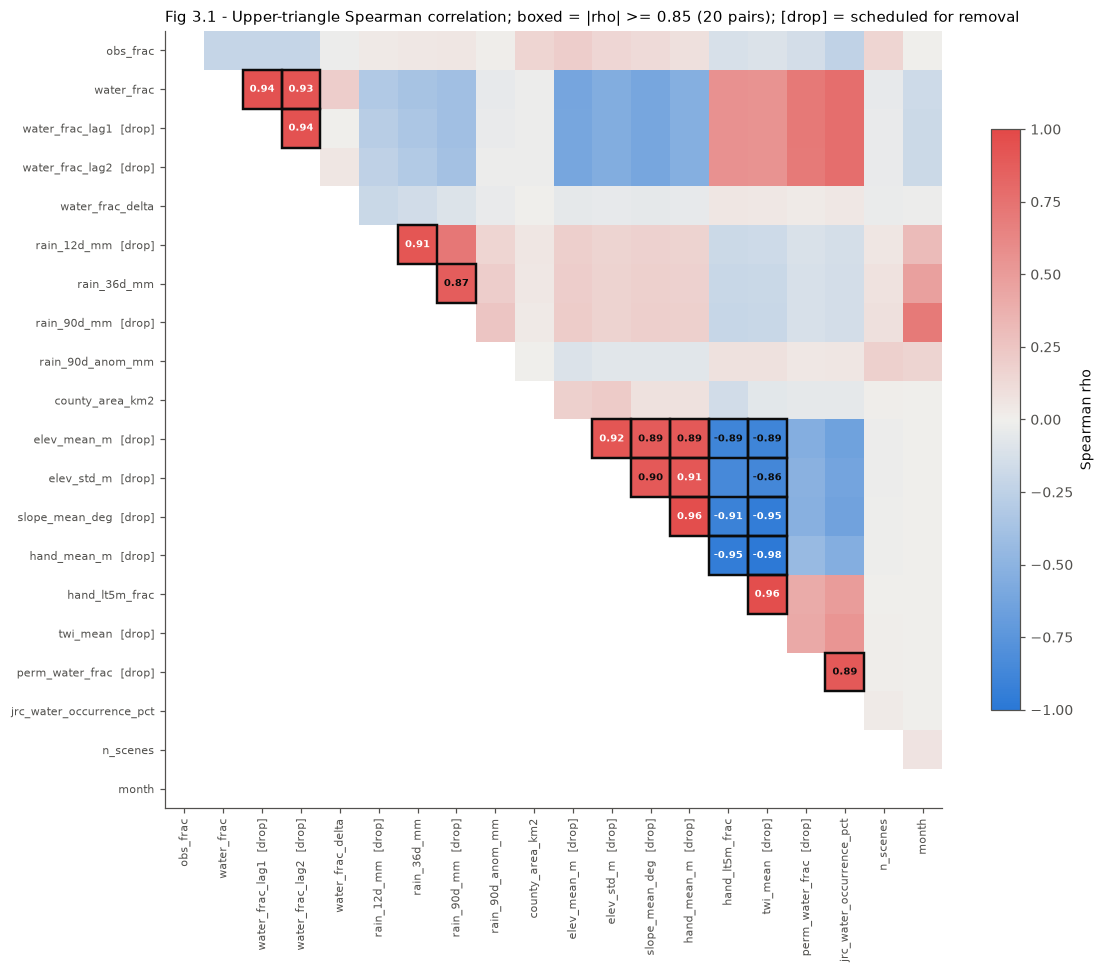

In [15]:
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
labels = [f"{c}  [drop]" if c in pipeline_drop else c for c in num]
R = rho.values.copy(); R[np.tril_indices_from(R)] = np.nan
fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(R, cmap=div, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(num))); ax.set_xticklabels(labels, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(num))); ax.set_yticklabels(labels, fontsize=7.5)
for i in range(len(num)):
    for j in range(i + 1, len(num)):
        v = rho.values[i, j]
        if abs(v) >= 0.85:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=INK, lw=1.6))
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.3, color="white" if abs(v) > 0.9 else INK, fontweight="bold")
cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.set_label("Spearman rho")
ax.set_title(f"Fig 3.1 - Upper-triangle Spearman correlation; boxed = |rho| >= 0.85 ({len(pairs)} pairs); [drop] = scheduled for removal",
             loc="left", fontsize=10)
fig.tight_layout(); save(fig, "fig3_1_correlation_matrix.png")

### Fig 3.2 — Collinear feature pairs with fitted linear trendlines
One panel per feature the pipeline removes (Phase 1 drop list), paired with the feature it collided with in Phase 1; rho is recomputed on Phase 2 training rows. Static terrain features have one value per county, so
those panels plot the 79 counties; dynamic panels plot a random sample of 3,000 training rows. Water fractions are shown on the
`log1p(100·x)` scale used by the pipeline, because their raw skew (≈ 22) would hide the relationship.

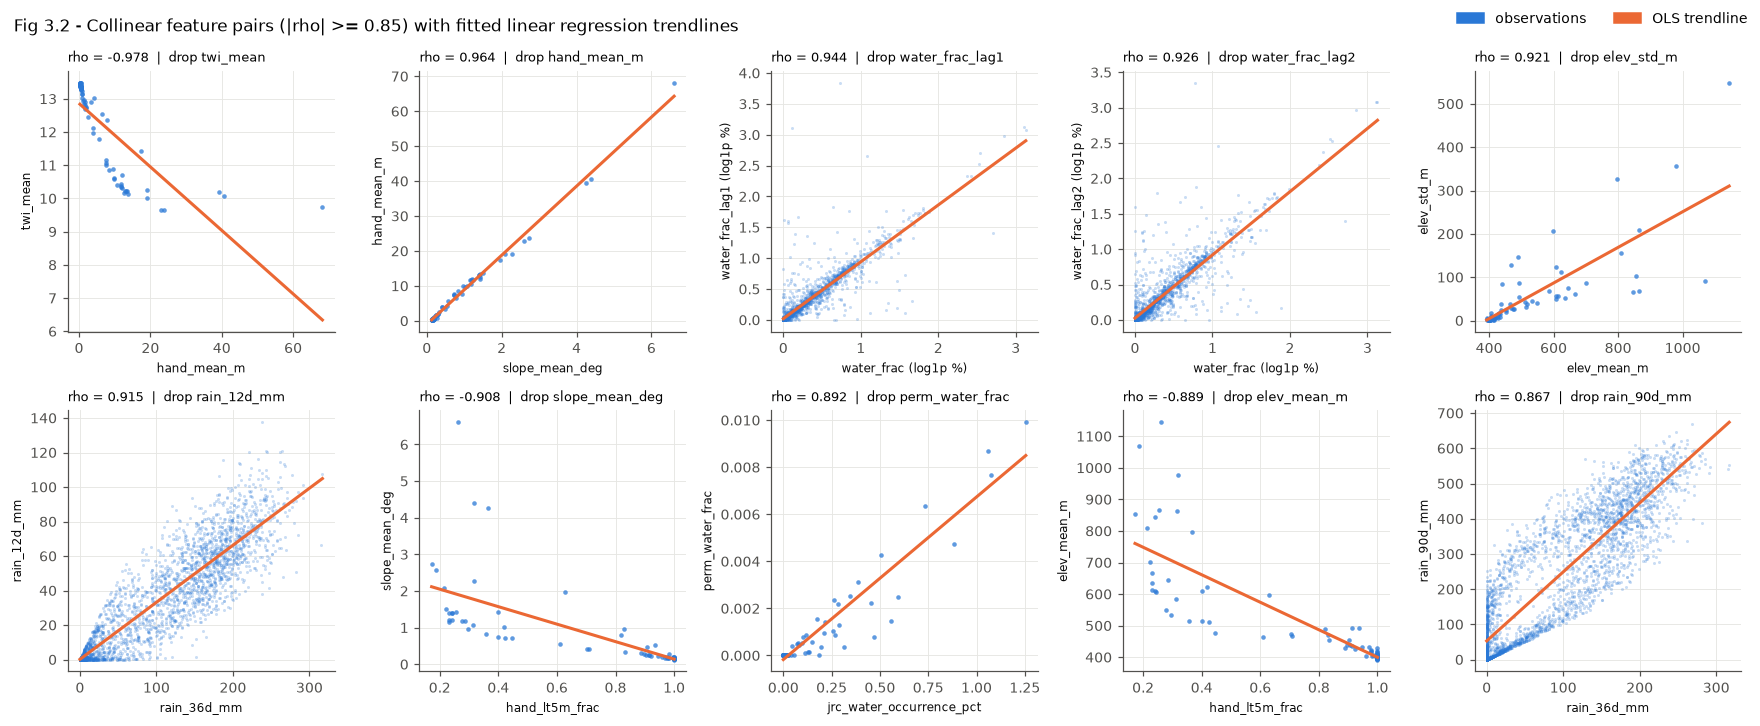

In [16]:
static = {"county_area_km2", "elev_mean_m", "elev_std_m", "slope_mean_deg", "hand_mean_m", "hand_lt5m_frac", "twi_mean", "perm_water_frac", "jrc_water_occurrence_pct"}
water = {"water_frac", "water_frac_lag1", "water_frac_lag2"}
sample = tr.sample(3000, random_state=SEED)
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6)); axes = axes.ravel()
for ax, (d, k, r) in zip(axes, p1[["feature", "partner", "rho_phase2"]].itertuples(index=False)):
    src = tr.drop_duplicates("adm2_pcode") if d in static and k in static else sample
    xv, yv = src[k].astype(float), src[d].astype(float)
    if k in water: xv = log1p_percent(xv)
    if d in water: yv = log1p_percent(yv)
    ok = np.isfinite(xv) & np.isfinite(yv); xv, yv = np.asarray(xv)[ok], np.asarray(yv)[ok]
    ax.scatter(xv, yv, s=9 if len(xv) < 100 else 4, color=BLUE, alpha=0.75 if len(xv) < 100 else 0.25, linewidths=0)
    b, a = np.polyfit(xv, yv, 1); xs = np.linspace(xv.min(), xv.max(), 50)
    ax.plot(xs, a + b * xs, color=ORANGE, lw=2)
    ax.set_xlabel(k + (" (log1p %)" if k in water else ""), fontsize=8); ax.set_ylabel(d + (" (log1p %)" if d in water else ""), fontsize=8)
    ax.set_title(f"rho = {r}  |  drop {d}", fontsize=8.5, loc="left")
for ax in axes[len(p1):]: ax.axis("off")
fig.legend(handles=[Patch(color=BLUE, label="observations"), Patch(color=ORANGE, label="OLS trendline")], loc="upper right", ncol=2)
fig.suptitle("Fig 3.2 - Collinear feature pairs (|rho| >= 0.85) with fitted linear regression trendlines", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "fig3_2_collinear_scatterplots.png")

### Fig 3.3 — Feature-to-target importance (mutual information, training rows)

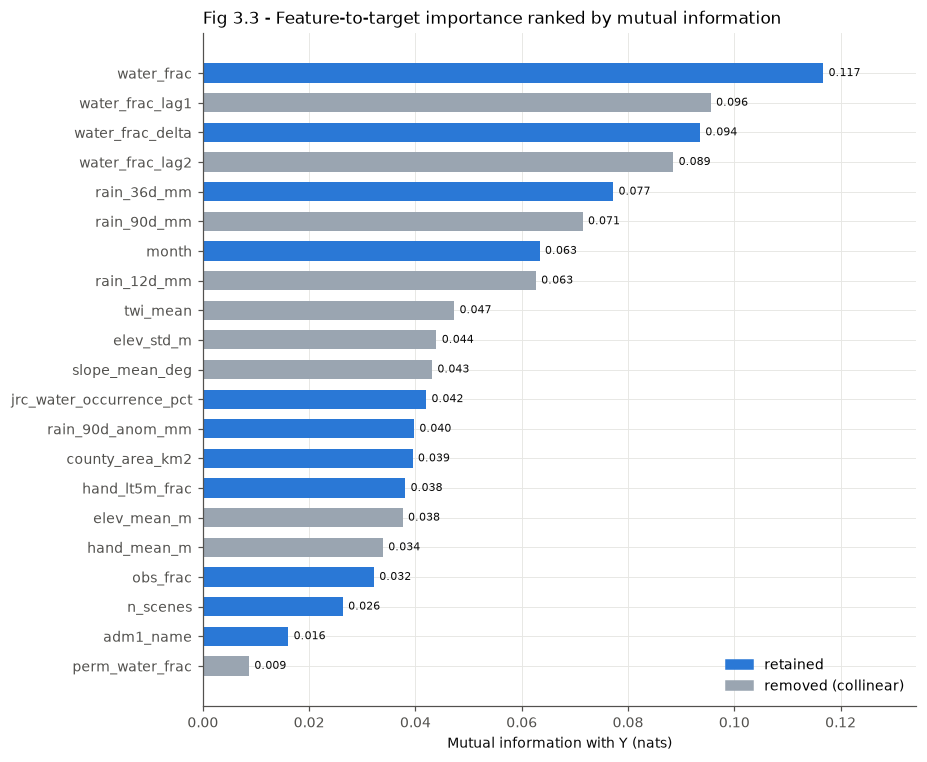

In [17]:
imp = mi.sort_values()
final_inputs = {c for c in num if c not in pipeline_drop} | {"adm1_name"}
fig, ax = plt.subplots(figsize=(8.5, 7))
cols_ = [BLUE if f in final_inputs else GRAY for f in imp.index]
ax.barh(imp.index, imp.values, color=cols_, height=0.65)
for i, v in enumerate(imp.values): ax.text(v + 0.001, i, f"{v:.3f}", va="center", fontsize=7.5, color=INK)
ax.set_xlabel("Mutual information with Y (nats)"); ax.set_xlim(0, imp.max() * 1.15)
ax.legend(handles=[Patch(color=BLUE, label="retained"), Patch(color=GRAY, label="removed (collinear)")], loc="lower right")
ax.set_title("Fig 3.3 - Feature-to-target importance ranked by mutual information", loc="left", fontsize=11)
fig.tight_layout(); save(fig, "fig3_3_target_importance.png")

## 5. Transformation stages (Phase 1, Section V-B)
`water_frac` is the most skewed retained feature, so it illustrates the chain: raw → `log1p(100·x)` → Min-Max → StandardScaler
(the pipeline itself uses log → StandardScaler for this feature; Min-Max is shown because the assignment asks for the four-stage comparison).

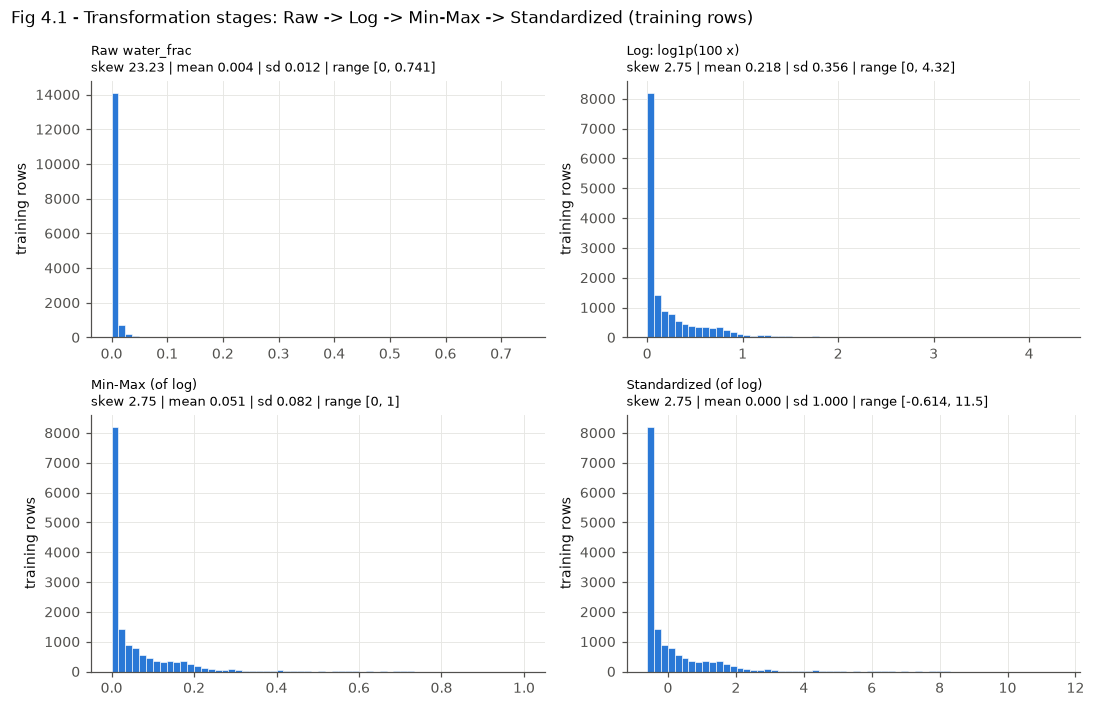

In [18]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
w = X_train["water_frac"].dropna().values.reshape(-1, 1)
stages = {"Raw water_frac": w, "Log: log1p(100 x)": log1p_percent(w)}
stages["Min-Max (of log)"] = MinMaxScaler().fit_transform(stages["Log: log1p(100 x)"])
stages["Standardized (of log)"] = StandardScaler().fit_transform(stages["Log: log1p(100 x)"])
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5)); axes = axes.ravel()
for ax, (name, v) in zip(axes, stages.items()):
    v = v.ravel(); ax.hist(v, bins=60, color=BLUE, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{name}\nskew {stats.skew(v):.2f} | mean {v.mean():.3f} | sd {v.std():.3f} | range [{v.min():.3g}, {v.max():.3g}]", fontsize=8.5, loc="left")
    ax.set_ylabel("training rows")
fig.suptitle("Fig 4.1 - Transformation stages: Raw -> Log -> Min-Max -> Standardized (training rows)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); save(fig, "fig4_1_transformation_grid.png")

## 6. Full pipeline — fit on `X_train` only, transform validation and test

`src/pipeline_builder.build_preprocessor()` = `GroupMedianImputer → MomentumFeature → OutlierCapper(Z) → OutlierCapper(IQR) → ColumnTransformer`.
`fit_transform` is called once, on `X_train`; validation and test only go through `transform`.

In [19]:
pre = PB.build_preprocessor()
Z_train = pre.fit_transform(X_train)
Z_val, Z_test = pre.transform(X_val), pre.transform(X_test)
feat = list(pre.named_steps["columns"].get_feature_names_out())
for name, Z in [("train", Z_train), ("validation", Z_val), ("test", Z_test)]:
    assert not np.isnan(Z).any(), name
    print(f"{name:<10} {X_train.shape[1] if name == 'train' else Z.shape[0]:>6} -> {Z.shape}")
print(f"\n{len(feat)} output features:", feat)
for name, Z, y, X in [("train", Z_train, y_train, X_train), ("validation", Z_val, y_val, X_val), ("test", Z_test, y_test, X_test)]:
    out = pd.DataFrame(Z, columns=feat)
    out.insert(0, "issue_date", X["issue_date"].dt.date.values); out.insert(0, "adm2_pcode", X["adm2_pcode"].values)
    out[TARGET] = y.values
    if "processed_paths" not in globals():
        processed_paths = {}

    path = PROC / f"{name}_processed.csv"
    try:
        out.to_csv(path, index=False)
    except PermissionError:
        locked = path
        path = PROC / f"{name}_processed_{pd.Timestamp.now():%Y%m%d_%H%M%S_%f}.csv"
        out.to_csv(path, index=False)
        print(f"{locked.name} is locked (open in Excel?); saved instead to {path.name}")

    processed_paths[name] = path
joblib.dump(pre, PROC / "preprocessor.joblib")
pd.Series(feat, name="feature").to_csv(PROC / "feature_names.csv", index=False)
print("saved:", sorted(p.name for p in PROC.glob("*") if not p.name.startswith(".")))

train          25 -> (15424, 23)
validation   2792 -> (2792, 23)
test         2662 -> (2662, 23)

23 output features: ['water_frac', 'county_area_km2', 'jrc_water_occurrence_pct', 'obs_frac', 'hand_lt5m_frac', 'water_frac_delta', 'rain_36d_mm', 'rain_90d_anom_mm', 'n_scenes', 'adm1_name_Abyei Region', 'adm1_name_Central Equatoria', 'adm1_name_Eastern Equatoria', 'adm1_name_Jonglei', 'adm1_name_Lakes', 'adm1_name_Northern Bahr el Ghazal', 'adm1_name_Unity', 'adm1_name_Upper Nile', 'adm1_name_Warrap', 'adm1_name_Western Bahr el Ghazal', 'adm1_name_Western Equatoria', 'month_sin', 'month_cos', 'water_frac_was_missing']


saved: ['feature_names.csv', 'preprocessor.joblib', 'test_processed.csv', 'train_processed.csv', 'validation_processed.csv']


### 6b. Processed dataset snapshots and statistics

The tables below show the model-ready matrices written to `data/processed/`. Because every scaler was fitted on training rows only,
the training columns have mean ≈ 0 and standard deviation ≈ 1 for standardised features (and [0, 1] for Min-Max ones), while validation
and test are allowed to differ — that difference is the real distribution shift between periods, not an error.

In [20]:
proc = {s: pd.DataFrame(Z, columns=feat) for s, Z in [("train", Z_train), ("validation", Z_val), ("test", Z_test)]}
for s, d in proc.items():
    print(f"{s}: {d.shape[0]:,} rows x {d.shape[1]} features | missing cells: {int(d.isna().sum().sum())} | "
          f"Y=1: {int({'train': y_train, 'validation': y_val, 'test': y_test}[s].sum()):,}")
print("\nSnapshot of the processed training matrix (first 6 rows):")
display(proc["train"].head(6).round(3))

train: 15,424 rows x 23 features | missing cells: 0 | Y=1: 2,926
validation: 2,792 rows x 23 features | missing cells: 0 | Y=1: 1,030
test: 2,662 rows x 23 features | missing cells: 0 | Y=1: 980

Snapshot of the processed training matrix (first 6 rows):


,water_frac,county_area_km2,jrc_water_occurrence_pct,obs_frac,hand_lt5m_frac,water_frac_delta,rain_36d_mm,rain_90d_anom_mm,n_scenes,adm1_name_Abyei Region,adm1_name_Central Equatoria,adm1_name_Eastern Equatoria,adm1_name_Jonglei,adm1_name_Lakes,adm1_name_Northern Bahr el Ghazal,adm1_name_Unity,adm1_name_Upper Nile,adm1_name_Warrap,adm1_name_Western Bahr el Ghazal,adm1_name_Western Equatoria,month_sin,month_cos,water_frac_was_missing
0,-0.139,0.774,-0.627,1.000,1.000,0.104,-1.198,-0.522,0.335,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.122,1.594,0.212,1.000,0.276,0.154,-1.157,-0.300,0.335,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.587,-1.320,-0.399,1.000,0.000,-0.000,-1.092,-0.395,0.335,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.616,-0.836,-0.638,0.999,0.100,-0.002,-1.052,0.173,0.335,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.616,-2.277,-0.638,1.000,0.017,-0.002,-1.092,0.426,0.335,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,0.093,0.799,0.103,1.000,0.648,0.026,-1.184,-0.312,0.335,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [21]:
side = pd.concat({s: d.agg(["mean", "std", "min", "max"]).T for s, d in proc.items()}, axis=1).round(3)
side

train                        validation                          test                       
                                    mean    std     min     max       mean    std     min     max   mean    std     min     max
water_frac                        -0.000  1.000  -0.616  11.587      0.335  1.558  -0.616   8.389  0.430  1.762  -0.616   8.243
county_area_km2                   -0.000  1.000  -3.084   3.379     -0.034  0.935  -3.084   3.379  0.009  1.028  -3.084   3.379
jrc_water_occurrence_pct           0.000  1.000  -0.638   3.685     -0.027  0.979  -0.638   3.685  0.013  1.006  -0.638   3.685
obs_frac                           0.967  0.138   0.000   1.000      0.924  0.194   0.000   1.000  0.960  0.173   0.000   1.000
hand_lt5m_frac                     0.678  0.386   0.000   1.000      0.670  0.391   0.000   1.000  0.686  0.383   0.000   1.000
water_frac_delta                   0.000  1.000 -64.588  64.673      0.000  0.611 -12.896  12.962  0.018  0.658 -13.742  15.789
rain_36d_mm                        0.000  1.000  -1.198   2.925     -0.239  0.914  -1.198   2.447  0.036  0.950  -1.198   3.000
rain_90d_anom_mm                  -0.000  1.000  -3.084   3.094     -0.131  0.860  -3.084   3.094 -0.266  1.196  -3.084   3.094
n_scenes                           0.000  1.000  -2.389   1.243     -1.302  0.653  -2.250   0.824  1.090  1.041  -0.434   3.967
adm1_name_Abyei Region             0.010  0.098   0.000   1.000      0.002  0.046   0.000   1.000  0.013  0.114   0.000   1.000
adm1_name_Central Equatoria        0.082  0.274   0.000   1.000      0.091  0.288   0.000   1.000  0.075  0.263   0.000   1.000
adm1_name_Eastern Equatoria        0.108  0.311   0.000   1.000      0.123  0.329   0.000   1.000  0.105  0.307   0.000   1.000
adm1_name_Jonglei                  0.148  0.355   0.000   1.000      0.166  0.372   0.000   1.000  0.139  0.346   0.000   1.000
adm1_name_Lakes                    0.109  0.311   0.000   1.000      0.123  0.328   0.000   1.000  0.100  0.300   0.000   1.000
adm1_name_Northern Bahr el Ghazal  0.049  0.215   0.000   1.000      0.009  0.094   0.000   1.000  0.062  0.242   0.000   1.000
adm1_name_Unity                    0.118  0.322   0.000   1.000      0.126  0.332   0.000   1.000  0.115  0.319   0.000   1.000
adm1_name_Upper Nile               0.135  0.342   0.000   1.000      0.121  0.326   0.000   1.000  0.151  0.358   0.000   1.000
adm1_name_Warrap                   0.078  0.268   0.000   1.000      0.081  0.272   0.000   1.000  0.077  0.267   0.000   1.000
adm1_name_Western Bahr el Ghazal   0.033  0.177   0.000   1.000      0.018  0.133   0.000   1.000  0.037  0.189   0.000   1.000
adm1_name_Western Equatoria        0.132  0.338   0.000   1.000      0.140  0.347   0.000   1.000  0.125  0.330   0.000   1.000
month_sin                         -0.001  0.711  -1.000   1.000      0.225  0.684  -1.000   1.000 -0.022  0.678  -1.000   1.000
month_cos                         -0.013  0.704  -1.000   1.000      0.077  0.690  -1.000   1.000 -0.108  0.727  -1.000   1.000
water_frac_was_missing             0.017  0.131   0.000   1.000      0.035  0.185   0.000   1.000  0.039  0.195   0.000   1.000

## 7. PCA diagnostic — Fig 5.1 (fitted on transformed training rows only)

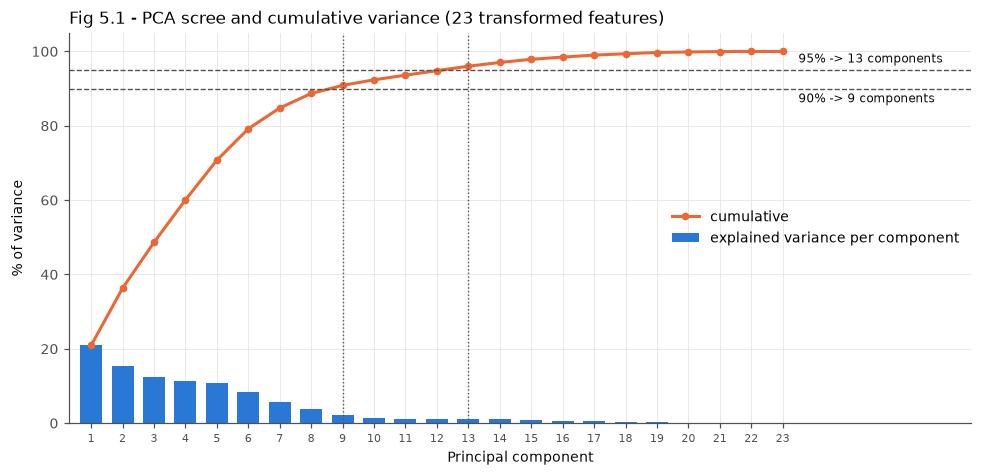

90% variance: 9 components | 95%: 13 components (of 23)


In [22]:
pca = PCA(random_state=SEED).fit(Z_train)
ev = pca.explained_variance_ratio_ * 100; cum = ev.cumsum()
k90, k95 = int(np.argmax(cum >= 90) + 1), int(np.argmax(cum >= 95) + 1)
fig, ax = plt.subplots(figsize=(9, 4.4))
ks = np.arange(1, len(ev) + 1)
ax.bar(ks, ev, color=BLUE, width=0.7, label="explained variance per component")
ax.plot(ks, cum, color=ORANGE, lw=2, marker="o", markersize=4, label="cumulative")
for t, k in [(90, k90), (95, k95)]:
    ax.axhline(t, color=MUTED, ls="--", lw=0.9); ax.axvline(k, color=MUTED, ls=":", lw=0.9)
    ax.text(len(ev) + 0.5, t + (1.2 if t == 95 else -1.2), f"{t}% -> {k} components", va="bottom" if t == 95 else "top", fontsize=8, color=INK)
ax.set_xlabel("Principal component"); ax.set_ylabel("% of variance"); ax.set_ylim(0, 105); ax.set_xlim(0.3, len(ev) + 6)
ax.set_xticks(ks); ax.tick_params(axis="x", labelsize=7); ax.legend(loc="center right")
ax.set_title(f"Fig 5.1 - PCA scree and cumulative variance ({Z_train.shape[1]} transformed features)", loc="left", fontsize=11)
fig.tight_layout(); save(fig, "fig5_1_pca_scree_plot.png")
print(f"90% variance: {k90} components | 95%: {k95} components (of {len(ev)})")

## 8. Output verification and strategy-vs-reality checks

**(a) Information loss from the collinearity reduction.** A light logistic-regression baseline (`class_weight="balanced"`) is wrapped in the
full pipeline and scored with average precision (PR-AUC) under `TimeSeriesSplit(n_splits=5, gap=2 windows × 79 rows)` on training rows, and once
on validation. The un-reduced pipeline (`drop=[]`) is the reference. This verifies the preprocessing; it is not the final model. **Test is not scored.**

In [23]:
cv = PB.temporal_cv(n_splits=5, gap_windows=GAP)
configs = {"full (no collinearity drop)": dict(drop=[], momentum=False), "reduced (Phase 1 drop list)": dict(momentum=False),
           "reduced + momentum (final)": dict()}
ver = {}
for name, kw in configs.items():
    pipe = PB.build_pipeline(LogisticRegression(class_weight="balanced", max_iter=3000), **kw)
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    pipe.fit(X_train, y_train)
    n_feat = len(pipe.named_steps["columns"].get_feature_names_out())
    ver[name] = {"n_features": n_feat, "cv_pr_auc_mean": round(s.mean(), 4), "cv_pr_auc_sd": round(s.std(), 4),
                 "val_pr_auc": round(average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1]), 4)}
ver_tbl = pd.DataFrame(ver).T
print("prevalence (PR-AUC of a random model): train", round(y_train.mean(), 3), "| validation", round(y_val.mean(), 3))
ver_tbl

prevalence (PR-AUC of a random model): train 0.19 | validation 0.369


,n_features,cv_pr_auc_mean,cv_pr_auc_sd,val_pr_auc
full (no collinearity drop),34.0,0.5341,0.1040,0.8305
reduced (Phase 1 drop list),22.0,0.5482,0.1042,0.8317
reduced + momentum (final),23.0,0.5498,0.1064,0.8328


**(b) Spatial robustness (Phase 1, VI-C).** `GroupKFold` by county inside the training period — counties in the scoring fold are never seen in fitting.

In [24]:
gkf = GroupKFold(n_splits=5)
s_g = cross_val_score(PB.build_pipeline(LogisticRegression(class_weight="balanced", max_iter=3000)), X_train, y_train,
                      groups=X_train["adm2_pcode"], cv=gkf, scoring="average_precision")
print(f"GroupKFold (unseen counties) PR-AUC: {s_g.mean():.4f} +/- {s_g.std():.4f}")

GroupKFold (unseen counties) PR-AUC: 0.6121 +/- 0.0495


**(c) Sensor-effect check (promised in Phase 1, III-D).** If more Sentinel-1 scenes per window (Sentinel-1C/D from mid-2025) inflated
exceedances, the positive rate would rise with `n_scenes` within the same season. Compared within wet-season months (Jul–Nov) only.

In [25]:
era = pd.cut(lab["issue_date"], [pd.Timestamp("2016-12-31"), pd.Timestamp("2021-12-23"), pd.Timestamp("2025-06-30"), pd.Timestamp("2027-01-01")],
             labels=["S1A+S1B 2017-21", "S1A only 2022-mid25", "S1A+S1C/D mid25-26"])
wet = lab["issue_date"].dt.month.between(7, 11)
sens = lab[wet].groupby(era[wet], observed=True).agg(rows=(TARGET, "size"), pos_rate=(TARGET, "mean"), median_scenes=("n_scenes", "median"))
sens["pos_rate"] = (100 * sens["pos_rate"]).round(1)
by_year = lab[wet].groupby(lab.loc[wet, "issue_date"].dt.year)[TARGET].mean().mul(100).round(1)
print("wet-season positive rate by year (%):", by_year.to_dict())
sens

wet-season positive rate by year (%): {2017: 10.7, 2018: 6.8, 2019: 1.7, 2020: 1.7, 2021: 6.2, 2022: 16.2, 2023: 20.1, 2024: 20.9, 2025: 28.7, 2026: 35.4}


,rows,pos_rate,median_scenes
issue_date,,,
S1A+S1B 2017-21,4970,5.3,65.0
S1A only 2022-mid25,2337,19.1,34.0
S1A+S1C/D mid25-26,1281,30.8,68.0


**(d) Label sensitivity (promised in Phase 1, II).** Results of `src/label_sensitivity.py` (Earth Engine; decision rule fixed before running).

In [26]:
LS = json.loads((ROOT / "phase2_implementation/label_sensitivity.json").read_text())
print("decision rule:", LS["decision_rule"]); print("adopted:", LS["adopted"])
pd.DataFrame(LS["results"]).T

decision rule: adopt only if median within-county rho improves >= 0.10 and pooled rho drops <= 0.05
adopted: ['vv18 (Phase 1 label kept)']


,pooled_rho,median_within_county_rho,core_median_within_county_rho,n_counties,adopt
vv18,0.696,0.064,0.163,58,False
vv16,0.617,0.065,0.111,62,False
vh22,0.523,0.008,0.052,63,False
vh24,0.612,0.079,0.121,62,False
vh26,0.678,0.129,0.306,59,False


### Save the Phase 2 summary used by the final report

In [27]:
summary = {
    "phase1_reproduced": {"N": N, "P": P, "overall_missing_pct": overall_missing, "complete_rows": complete_rows},
    "split": {k: {kk: str(vv) for kk, vv in v.items()} for k, v in split_tbl.T.to_dict().items()},
    "purged_rows": n_purged, "purged_windows": len(purged), "labelled_used": len(lab),
    "capping": cap_rows, "collinear_pairs": len(pairs), "pairs_list": [[x, y, round(float(r), 3)] for x, y, r in pairs], "drop_phase2": phase2_drop, "drop_pipeline": pipeline_drop,
    "terrain_mi": {k: round(float(v), 4) for k, v in mi[static_feats].items()},
    "drop_matches_phase1": phase2_drop == sorted(PB.DROP_COLLINEAR),
    "momentum": {"max_abs_rho_with_retained": round(float(rho.loc["water_frac_delta", [k for k in kept if k != "water_frac_delta"]].abs().max()), 3),
                 "mi": round(float(mi["water_frac_delta"]), 4)},
    "mi": {k: round(float(v), 4) for k, v in mi.sort_values(ascending=False).items()},
    "water_frac_skew_stages": {k: round(float(stats.skew(v.ravel())), 3) for k, v in stages.items()},
    "processed_shapes": {"train": list(Z_train.shape), "validation": list(Z_val.shape), "test": list(Z_test.shape)},
    "raw_feature_columns": int(X_train.shape[1]), "output_features": feat,
    "pca": {"k90": k90, "k95": k95, "n_components": int(len(ev)), "first5_pct": [round(float(v), 2) for v in ev[:5]]},
    "verification": ver, "groupkfold_pr_auc": [round(float(s_g.mean()), 4), round(float(s_g.std()), 4)],
    "prevalence": {"train": round(float(y_train.mean()), 4), "validation": round(float(y_val.mean()), 4)},
    "sensor_check": {"by_era": {str(k): v for k, v in sens["pos_rate"].to_dict().items()}, "wet_by_year": {int(k): v for k, v in by_year.to_dict().items()}},
    "label_sensitivity": LS,
}
(ROOT / "phase2_implementation/phase2_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written phase2_implementation/phase2_summary.json")

written phase2_implementation/phase2_summary.json


In [28]:
raw.shape

(23305, 26)

In [29]:
pd.read_csv(PROC / "train_processed.csv").head(10)  

,adm2_pcode,issue_date,water_frac,county_area_km2,jrc_water_occurrence_pct,obs_frac,hand_lt5m_frac,water_frac_delta,rain_36d_mm,rain_90d_anom_mm,n_scenes,adm1_name_Abyei Region,adm1_name_Central Equatoria,adm1_name_Eastern Equatoria,adm1_name_Jonglei,adm1_name_Lakes,adm1_name_Northern Bahr el Ghazal,adm1_name_Unity,adm1_name_Upper Nile,adm1_name_Warrap,adm1_name_Western Bahr el Ghazal,adm1_name_Western Equatoria,month_sin,month_cos,water_frac_was_missing,y_flood_2_4wk
0,SS0001,2017-01-12,-0.139300,0.774091,-0.627158,1.000000,1.000000,0.104426,-1.198450,-0.522131,0.334769,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
1,SS0101,2017-01-12,0.122074,1.594488,0.211571,1.000000,0.275658,0.154029,-1.156980,-0.299592,0.334769,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
2,SS0102,2017-01-12,-0.587285,-1.319710,-0.398816,0.999765,0.000000,-0.000004,-1.091667,-0.394663,0.334769,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
3,SS0103,2017-01-12,-0.616442,-0.836380,-0.638014,0.998792,0.099512,-0.002293,-1.051660,0.173387,0.334769,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
4,SS0104,2017-01-12,-0.616442,-2.277377,-0.638091,1.000000,0.017232,-0.002293,-1.091821,0.425549,0.334769,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
5,SS0105,2017-01-12,0.092919,0.798511,0.102905,0.999956,0.647714,0.025766,-1.184038,-0.311539,0.334769,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
6,SS0106,2017-01-12,-0.616442,0.120486,-0.637928,1.000000,0.082595,-0.002293,-1.048141,0.348822,0.334769,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
7,SS0201,2017-01-12,-0.454098,-0.112429,-0.638078,1.000000,0.175791,0.039295,-1.091663,-0.640573,0.334769,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
8,SS0202,2017-01-12,-0.590049,-0.831285,-0.638090,1.000000,0.108788,0.005991,-1.088814,-0.560311,0.334769,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
9,SS0203,2017-01-12,2.263865,2.292396,-0.626437,0.999506,0.551385,1.361589,-1.103226,-1.545164,0.334769,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
